In [1]:
!pip install biopython
!pip install transformers
!pip install torch
!pip install pandas


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 4.6 MB/s eta 0:00:00


In [2]:
import os
import urllib.request
import pandas as pd

from Bio.PDB import PDBParser
from Bio.SeqUtils import seq1

In [3]:
protein_ids = [
    "1LYZ",
    "206L",
    "1A4Y",
    "1BLI",
    "1TIM",
    "1AKE",
    "1AKY",
    "1CA2",
    "1GCT",
    "1HCL",
    "1STP",
    "2PTC",
    "1PPN",
    "1YLC",
    "1LZ1",
    "1HEL",
    "1EJG",
    "1A0J",
    "1B73",
    "1J2U"
]

print(protein_ids)

['1LYZ', '206L', '1A4Y', '1BLI', '1TIM', '1AKE', '1AKY', '1CA2', '1GCT', '1HCL', '1STP', '2PTC', '1PPN', '1YLC', '1LZ1', '1HEL', '1EJG', '1A0J', '1B73', '1J2U']


In [4]:
import os

os.makedirs("data/pdb", exist_ok=True)

for pdb_id in protein_ids:

    url = f"https://files.rcsb.org/download/{pdb_id}.pdb"

    file_path = f"data/pdb/{pdb_id}.pdb"

    urllib.request.urlretrieve(url, file_path)

    print(f"{pdb_id} downloaded successfully!")

1LYZ downloaded successfully!
206L downloaded successfully!
1A4Y downloaded successfully!
1BLI downloaded successfully!
1TIM downloaded successfully!
1AKE downloaded successfully!
1AKY downloaded successfully!
1CA2 downloaded successfully!
1GCT downloaded successfully!
1HCL downloaded successfully!
1STP downloaded successfully!
2PTC downloaded successfully!
1PPN downloaded successfully!
1YLC downloaded successfully!
1LZ1 downloaded successfully!
1HEL downloaded successfully!
1EJG downloaded successfully!
1A0J downloaded successfully!
1B73 downloaded successfully!
1J2U downloaded successfully!


In [5]:
from Bio.PDB import PDBParser
from Bio.SeqUtils import seq1
import pandas as pd

In [6]:
parser = PDBParser(QUIET=True)

In [7]:
protein_sequences = []

for pdb_id in protein_ids:

    structure = parser.get_structure(
        pdb_id,
        f"data/pdb/{pdb_id}.pdb"
    )

    model = structure[0]

    chain = list(model.get_chains())[0]

    sequence = ""

    for residue in chain:

        if residue.id[0] != " ":
            continue

        sequence += seq1(residue.get_resname())

    protein_sequences.append(
        [pdb_id, sequence, len(sequence)]
    )

sequence_df = pd.DataFrame(
    protein_sequences,
    columns=[
        "PDB_ID",
        "Sequence",
        "Length"
    ]
)

sequence_df

,PDB_ID,Sequence,Length
0,1LYZ,KVFGRCELAAAMKRHGLDNYRGYSLGNWVCAAKFESNFNTQATNRN...,129
1,206L,MNIFEMLRIDEGLRLKIYKDTEGYYTIGIGHLLTKSPSLNASKSEL...,162
2,1A4Y,SLDIQSLDIQCEELSDARWAELLPLLQQCQVVRLDDCGLTEARCKD...,460
3,1BLI,LNGTLMQYFEWYMPNDGQHWKRLQNDSAYLAEHGITAVWIPPAYKG...,481
4,1TIM,APRKFFVGGNWKMNGKRKSLGELIHTLDGAKLSADTEVVCGAPSIY...,247
5,1AKE,MRIILLGAPGAGKGTQAQFIMEKYGIPQISTGDMLRAAVKSGSELG...,214
6,1AKY,ESIRMVLIGPPGAGKGTQAPNLQERFHAAHLATGDMLRSQIAKGTQ...,218
7,1CA2,HWGYGKHNGPEHWHKDFPIAKGERQSPVDIDTHTAKYDPSLKPLSV...,256
8,1GCT,CGVPAIQPVLS,11
9,1HCL,MENFQKVEKIGEGTYGVVYKARNKLTGEVVALKKIRTEGVPSTAIR...,294


In [8]:
model = structure[0]
chain = list(model.get_chains())[0]

sequence = ""

for residue in chain:

    if residue.id[0] != " ":
        continue

    sequence += seq1(residue.get_resname())

protein_sequences.append(
    [pdb_id, sequence, len(sequence)]
)

In [ ]:
sequence_df = pd.DataFrame(
    protein_sequences,
    columns=["PDB_ID", "Sequence", "Length"]
)

print(sequence_df)

print(sequence_df.shape)

   PDB_ID                                           Sequence  Length
0    1LYZ  KVFGRCELAAAMKRHGLDNYRGYSLGNWVCAAKFESNFNTQATNRN...     129
1    206L  MNIFEMLRIDEGLRLKIYKDTEGYYTIGIGHLLTKSPSLNASKSEL...     162
2    1A4Y  SLDIQSLDIQCEELSDARWAELLPLLQQCQVVRLDDCGLTEARCKD...     460
3    1BLI  LNGTLMQYFEWYMPNDGQHWKRLQNDSAYLAEHGITAVWIPPAYKG...     481
4    1TIM  APRKFFVGGNWKMNGKRKSLGELIHTLDGAKLSADTEVVCGAPSIY...     247
5    1AKE  MRIILLGAPGAGKGTQAQFIMEKYGIPQISTGDMLRAAVKSGSELG...     214
6    1AKY  ESIRMVLIGPPGAGKGTQAPNLQERFHAAHLATGDMLRSQIAKGTQ...     218
7    1CA2  HWGYGKHNGPEHWHKDFPIAKGERQSPVDIDTHTAKYDPSLKPLSV...     256
8    1GCT                                        CGVPAIQPVLS      11
9    1HCL  MENFQKVEKIGEGTYGVVYKARNKLTGEVVALKKIRTEGVPSTAIR...     294
10   1STP  AEAGITGTWYNQLGSTFIVTAGADGALTGTYESAVGNAESRYVLTG...     121
11   2PTC  IVGGYTCGANTVPYQVSLNSGYHFCGGSLINSQWVVSAAHCYKSGI...     223
12   1PPN  IPEYVDWRQKGAVTPVKNQGSCGSCWAFSAVVTIEGIIKIRTGNLN...     212
13   1YLC  IVGGYTCQENSVPYQVSLNSGYH

In [9]:
import requests

In [10]:
url = "https://www.ebi.ac.uk/thornton-srv/m-csa/api/residues/?format=json"

response = requests.get(url)

print(response.status_code)

200


In [11]:
data = response.json()

print(type(data))
print(len(data))

<class 'list'>
5248


In [12]:
print(data[0])


{'mcsa_id': 1, 'roles_summary': 'activator, electrostatic stabiliser, hydrogen bond acceptor, hydrogen bond donor, proton acceptor', 'function_location_abv': '', 'main_annotation': 'Acts as the general acid/base for Cys70 activation.', 'ptm': '', 'roles': [{'group_function': 'activator', 'function_type': 'spectator', 'function': 'activator', 'emo': 'EMO_00038'}, {'group_function': '', 'function_type': 'interaction', 'function': 'hydrogen bond acceptor', 'emo': 'EMO_00113'}, {'group_function': 'electrostatic interaction', 'function_type': 'spectator', 'function': 'electrostatic stabiliser', 'emo': 'EMO_00033'}, {'group_function': '', 'function_type': 'interaction', 'function': 'hydrogen bond donor', 'emo': 'EMO_00114'}, {'group_function': 'electrostatic interaction', 'function_type': 'spectator', 'function': 'electrostatic stabiliser', 'emo': 'EMO_00033'}, {'group_function': '', 'function_type': 'interaction', 'function': 'hydrogen bond donor', 'emo': 'EMO_00114'}, {'group_function': ''

In [13]:
import os
print(len(os.listdir("data/pdb")))
print(sequence_df.shape)

20
(20, 3)


In [14]:
# Checking for duplicates:
sequence_df[sequence_df.duplicated(subset="PDB_ID", keep=False)]

#Step 2: Remove duplicates
sequence_df = sequence_df.drop_duplicates(subset="PDB_ID")
print(sequence_df.shape)





(20, 3)


In [15]:
import os
os.makedirs("data/csv", exist_ok=True)
sequence_df.to_csv(
    "data/csv/protein_sequences.csv",
    index=False
)

In [16]:
saved_df = pd.read_csv("data/csv/protein_sequences.csv")

saved_df.head()

,PDB_ID,Sequence,Length
0,1LYZ,KVFGRCELAAAMKRHGLDNYRGYSLGNWVCAAKFESNFNTQATNRN...,129
1,206L,MNIFEMLRIDEGLRLKIYKDTEGYYTIGIGHLLTKSPSLNASKSEL...,162
2,1A4Y,SLDIQSLDIQCEELSDARWAELLPLLQQCQVVRLDDCGLTEARCKD...,460
3,1BLI,LNGTLMQYFEWYMPNDGQHWKRLQNDSAYLAEHGITAVWIPPAYKG...,481
4,1TIM,APRKFFVGGNWKMNGKRKSLGELIHTLDGAKLSADTEVVCGAPSIY...,247


In [17]:
import pandas as pd

sequence_df = pd.read_csv("data/csv/protein_sequences.csv")

sequence_df.head()

,PDB_ID,Sequence,Length
0,1LYZ,KVFGRCELAAAMKRHGLDNYRGYSLGNWVCAAKFESNFNTQATNRN...,129
1,206L,MNIFEMLRIDEGLRLKIYKDTEGYYTIGIGHLLTKSPSLNASKSEL...,162
2,1A4Y,SLDIQSLDIQCEELSDARWAELLPLLQQCQVVRLDDCGLTEARCKD...,460
3,1BLI,LNGTLMQYFEWYMPNDGQHWKRLQNDSAYLAEHGITAVWIPPAYKG...,481
4,1TIM,APRKFFVGGNWKMNGKRKSLGELIHTLDGAKLSADTEVVCGAPSIY...,247


In [18]:
rows = []
for _, row in sequence_df.iterrows():

    pdb = row["PDB_ID"]

    sequence = row["Sequence"]

    for i, aa in enumerate(sequence, start=1):

        rows.append([

            pdb,

            i,

            aa

        ])

In [19]:
enumerate(sequence, start=1)

In [20]:
residue_df = pd.DataFrame(

    rows,

    columns=[

        "PDB_ID",

        "Residue_No",

        "AA"

    ]

)
residue_df.head(20)
#Check the size.

print(residue_df.shape)

(4288, 3)


In [21]:
print(residue_df.head(10))
print(residue_df.shape)

  PDB_ID  Residue_No AA
0   1LYZ           1  K
1   1LYZ           2  V
2   1LYZ           3  F
3   1LYZ           4  G
4   1LYZ           5  R
5   1LYZ           6  C
6   1LYZ           7  E
7   1LYZ           8  L
8   1LYZ           9  A
9   1LYZ          10  A
(4288, 3)


In [22]:
hydrophobicity = {

"A":1.8,
"R":-4.5,
"N":-3.5,
"D":-3.5,
"C":2.5,
"Q":-3.5,
"E":-3.5,
"G":-0.4,
"H":-3.2,
"I":4.5,
"L":3.8,
"K":-3.9,
"M":1.9,
"F":2.8,
"P":-1.6,
"S":-0.8,
"T":-0.7,
"W":-0.9,
"Y":-1.3,
"V":4.2

}
# Step 2: Add hydrophobicity column
residue_df["Hydrophobicity"] = residue_df["AA"].map(hydrophobicity)

In [23]:
residue_df.head()

,PDB_ID,Residue_No,AA,Hydrophobicity
0,1LYZ,1,K,-3.9
1,1LYZ,2,V,4.2
2,1LYZ,3,F,2.8
3,1LYZ,4,G,-0.4
4,1LYZ,5,R,-4.5


In [24]:
residue_df["Hydrophobicity"] = residue_df["AA"].map(hydrophobicity)

residue_df.head()

,PDB_ID,Residue_No,AA,Hydrophobicity
0,1LYZ,1,K,-3.9
1,1LYZ,2,V,4.2
2,1LYZ,3,F,2.8
3,1LYZ,4,G,-0.4
4,1LYZ,5,R,-4.5


In [25]:
residue_df.head(10)

,PDB_ID,Residue_No,AA,Hydrophobicity
0,1LYZ,1,K,-3.9
1,1LYZ,2,V,4.2
2,1LYZ,3,F,2.8
3,1LYZ,4,G,-0.4
4,1LYZ,5,R,-4.5
5,1LYZ,6,C,2.5
6,1LYZ,7,E,-3.5
7,1LYZ,8,L,3.8
8,1LYZ,9,A,1.8
9,1LYZ,10,A,1.8


In [26]:
molecular_weight = {

"A":89.09,
"R":174.20,
"N":132.12,
"D":133.10,
"C":121.16,
"Q":146.15,
"E":147.13,
"G":75.07,
"H":155.16,
"I":131.17,
"L":131.17,
"K":146.19,
"M":149.21,
"F":165.19,
"P":115.13,
"S":105.09,
"T":119.12,
"W":204.23,
"Y":181.19,
"V":117.15

}

In [27]:
residue_df["Molecular_Weight"] = residue_df["AA"].map(molecular_weight)
residue_df.head(10)

,PDB_ID,Residue_No,AA,Hydrophobicity,Molecular_Weight
0,1LYZ,1,K,-3.9,146.19
1,1LYZ,2,V,4.2,117.15
2,1LYZ,3,F,2.8,165.19
3,1LYZ,4,G,-0.4,75.07
4,1LYZ,5,R,-4.5,174.20
5,1LYZ,6,C,2.5,121.16
6,1LYZ,7,E,-3.5,147.13
7,1LYZ,8,L,3.8,131.17
8,1LYZ,9,A,1.8,89.09
9,1LYZ,10,A,1.8,89.09


In [28]:
import numpy as np

In [29]:
coordinates = []

In [30]:
import numpy as np

parser = PDBParser(QUIET=True)


for pdb_id in sequence_df["PDB_ID"]:

    pdb_file = f"data/pdb/{pdb_id}.pdb"

    structure = parser.get_structure(
        pdb_id,
        pdb_file
    )

    model = structure[0]

    chain = list(model.get_chains())[0]


    for residue in chain:

        if residue.id[0] != " ":
            continue


        residue_no = residue.id[1]

        atoms = list(residue.get_atoms())


        x = np.mean(
            [atom.coord[0] for atom in atoms]
        )

        y = np.mean(
            [atom.coord[1] for atom in atoms]
        )

        z = np.mean(
            [atom.coord[2] for atom in atoms]
        )


        coordinates.append(
            [
                pdb_id,
                residue_no,
                x,
                y,
                z
            ]
        )
#Step 4: Convert to dataframe
coord_df = pd.DataFrame(
    coordinates,
    columns=[
        "PDB_ID",
        "Residue_No",
        "X",
        "Y",
        "Z"
    ]
)

In [31]:
coord_df.head()

,PDB_ID,Residue_No,X,Y,Z
0,1LYZ,1,0.531000,10.588889,8.832334
1,1LYZ,2,2.617857,14.040571,6.966714
2,1LYZ,3,-1.989636,14.669908,8.912545
3,1LYZ,4,-3.180750,17.699001,5.764250
4,1LYZ,5,-5.171545,22.657820,4.496546


In [32]:
residue_df = residue_df.merge(
    coord_df,
    on=["PDB_ID","Residue_No"],
    how="left"
)

In [33]:
residue_df.head()





,PDB_ID,Residue_No,AA,Hydrophobicity,Molecular_Weight,X,Y,Z
0,1LYZ,1,K,-3.9,146.19,0.531000,10.588889,8.832334
1,1LYZ,2,V,4.2,117.15,2.617857,14.040571,6.966714
2,1LYZ,3,F,2.8,165.19,-1.989636,14.669908,8.912545
3,1LYZ,4,G,-0.4,75.07,-3.180750,17.699001,5.764250
4,1LYZ,5,R,-4.5,174.20,-5.171545,22.657820,4.496546


In [34]:
print(coord_df.head())
print(coord_df.shape)

  PDB_ID  Residue_No         X          Y         Z
0   1LYZ           1  0.531000  10.588889  8.832334
1   1LYZ           2  2.617857  14.040571  6.966714
2   1LYZ           3 -1.989636  14.669908  8.912545
3   1LYZ           4 -3.180750  17.699001  5.764250
4   1LYZ           5 -5.171545  22.657820  4.496546
(4288, 5)


In [35]:
residue_df = residue_df.merge(
    coord_df,
    on=["PDB_ID","Residue_No"],
    how="left"
)

In [36]:
residue_df.head()

,PDB_ID,Residue_No,AA,Hydrophobicity,Molecular_Weight,X_x,Y_x,Z_x,X_y,Y_y,Z_y
0,1LYZ,1,K,-3.9,146.19,0.531000,10.588889,8.832334,0.531000,10.588889,8.832334
1,1LYZ,2,V,4.2,117.15,2.617857,14.040571,6.966714,2.617857,14.040571,6.966714
2,1LYZ,3,F,2.8,165.19,-1.989636,14.669908,8.912545,-1.989636,14.669908,8.912545
3,1LYZ,4,G,-0.4,75.07,-3.180750,17.699001,5.764250,-3.180750,17.699001,5.764250
4,1LYZ,5,R,-4.5,174.20,-5.171545,22.657820,4.496546,-5.171545,22.657820,4.496546


In [37]:
residue_df.isnull().sum()

,0
PDB_ID,0
Residue_No,0
AA,0
Hydrophobicity,0
Molecular_Weight,0
X_x,102
Y_x,102
Z_x,102
X_y,102
Y_y,102


In [38]:
residue_df = residue_df.drop(
    columns=[
        "X_y",
        "Y_y",
        "Z_y"
    ]
)
# Step 3: Rename coordinates

residue_df = residue_df.rename(
    columns={
        "X_x":"X",
        "Y_x":"Y",
        "Z_x":"Z"
    }
)
# Step 4: Check again

print(residue_df.head())

print(residue_df.isnull().sum())

  PDB_ID  Residue_No AA  Hydrophobicity  Molecular_Weight         X  \
0   1LYZ           1  K            -3.9            146.19  0.531000   
1   1LYZ           2  V             4.2            117.15  2.617857   
2   1LYZ           3  F             2.8            165.19 -1.989636   
3   1LYZ           4  G            -0.4             75.07 -3.180750   
4   1LYZ           5  R            -4.5            174.20 -5.171545   

           Y         Z  
0  10.588889  8.832334  
1  14.040571  6.966714  
2  14.669908  8.912545  
3  17.699001  5.764250  
4  22.657820  4.496546  
PDB_ID                0
Residue_No            0
AA                    0
Hydrophobicity        0
Molecular_Weight      0
X                   102
Y                   102
Z                   102
dtype: int64


In [39]:
missing = residue_df[
    residue_df["X"].isna()
]

missing["PDB_ID"].value_counts()

,count
PDB_ID,
1A0J,25
1YLC,25
2PTC,25
1STP,12
1CA2,4
1HCL,4
1AKY,2
1BLI,2
1J2U,2


In [40]:
residue_df = residue_df.dropna()
# Step 3: Verify


print(residue_df.shape)

print(residue_df.isnull().sum())

(4213, 8)
PDB_ID              0
Residue_No          0
AA                  0
Hydrophobicity      0
Molecular_Weight    0
X                   0
Y                   0
Z                   0
dtype: int64


In [41]:
from Bio.PDB import NeighborSearch

In [42]:
structure = parser.get_structure(
    "1LYZ",
    "data/pdb/1LYZ.pdb"
)

for residue in structure.get_residues():
    print(residue.get_resname())

LYS
VAL
PHE
GLY
ARG
CYS
GLU
LEU
ALA
ALA
ALA
MET
LYS
ARG
HIS
GLY
LEU
ASP
ASN
TYR
ARG
GLY
TYR
SER
LEU
GLY
ASN
TRP
VAL
CYS
ALA
ALA
LYS
PHE
GLU
SER
ASN
PHE
ASN
THR
GLN
ALA
THR
ASN
ARG
ASN
THR
ASP
GLY
SER
THR
ASP
TYR
GLY
ILE
LEU
GLN
ILE
ASN
SER
ARG
TRP
TRP
CYS
ASN
ASP
GLY
ARG
THR
PRO
GLY
SER
ARG
ASN
LEU
CYS
ASN
ILE
PRO
CYS
SER
ALA
LEU
LEU
SER
SER
ASP
ILE
THR
ALA
SER
VAL
ASN
CYS
ALA
LYS
LYS
ILE
VAL
SER
ASP
GLY
ASN
GLY
MET
ASN
ALA
TRP
VAL
ALA
TRP
ARG
ASN
ARG
CYS
LYS
GLY
THR
ASP
VAL
GLN
ALA
TRP
ILE
ARG
GLY
CYS
ARG
LEU
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH
HOH


In [43]:
!pip install bioservices

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 277.8/277.8 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.0/57.0 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.9/71.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.1/88.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 718.5/718.5 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 623.8/623.8 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.6/270.6 kB 5.7 MB/s eta 0:00:00
  Attempting uninstall: wrapt
    Found existing installat

In [44]:
from bioservices import UniProt

Creating directory /root/.config/bioservices 


In [45]:
u = UniProt()

Creating directory /root/.cache/bioservices 
Welcome to Bioservices
It looks like you do not have a configuration file.
We are creating one with default values in /root/.config/bioservices/bioservices.cfg .
Done


In [46]:
result = u.search(
    "1LYZ",
    frmt="tsv"
)

print(result[:500])

Entry	Entry Name	Reviewed	Protein names	Gene Names	Organism	Length
P00698	LYSC_CHICK	reviewed	Lysozyme C (EC 3.2.1.17) (1,4-beta-N-acetylmuramidase C) (Allergen Gal d IV) (allergen Gal d 4)	LYZ	Gallus gallus (Chicken)	147


In [47]:
id="4j6v2h"
result = u.retrieve("P00698", frmt="txt")

print(result[:2000])

ID   LYSC_CHICK              Reviewed;         147 AA.
AC   P00698; B8YJN9; B8YJP1; B8YJT7; B8YK79; Q90884;
DT   21-JUL-1986, integrated into UniProtKB/Swiss-Prot.
DT   21-JUL-1986, sequence version 1.
DT   02-SEP-2026, entry version 252.
DE   RecName: Full=Lysozyme C;
DE            EC=3.2.1.17;
DE   AltName: Full=1,4-beta-N-acetylmuramidase C;
DE   AltName: Full=Allergen Gal d IV;
DE   AltName: Allergen=Gal d 4;
DE   Flags: Precursor;
GN   Name=LYZ;
OS   Gallus gallus (Chicken).
OC   Eukaryota; Metazoa; Chordata; Craniata; Vertebrata; Euteleostomi;
OC   Archelosauria; Archosauria; Dinosauria; Saurischia; Theropoda;
OC   Coelurosauria; Aves; Neognathae; Galloanserae; Galliformes; Phasianidae;
OC   Phasianinae; Gallus.
OX   NCBI_TaxID=9031;
RN   [1]
RP   NUCLEOTIDE SEQUENCE [GENOMIC DNA], SEQUENCE REVISION TO 121, AND VARIANT
RP   VAL-49.
RX   PubMed=6934509; DOI=10.1073/pnas.77.10.5759;
RA   Jung A., Sippel A.E., Grez M., Schutz G.;
RT   "Exons encode functional and structural units of

In [51]:
def get_active_sites(uniprot_id):
    if not uniprot_id:
        return []
    try:
        uniprot_text = u.retrieve(uniprot_id, frmt="txt")
        return extract_active_sites(uniprot_text)
    except Exception as e:
        print(f"Error retrieving active sites for {uniprot_id}: {e}")
        return []

In [52]:
result = u.retrieve("P00698", frmt="txt")

print(result[:2000])

ID   LYSC_CHICK              Reviewed;         147 AA.
AC   P00698; B8YJN9; B8YJP1; B8YJT7; B8YK79; Q90884;
DT   21-JUL-1986, integrated into UniProtKB/Swiss-Prot.
DT   21-JUL-1986, sequence version 1.
DT   02-SEP-2026, entry version 252.
DE   RecName: Full=Lysozyme C;
DE            EC=3.2.1.17;
DE   AltName: Full=1,4-beta-N-acetylmuramidase C;
DE   AltName: Full=Allergen Gal d IV;
DE   AltName: Allergen=Gal d 4;
DE   Flags: Precursor;
GN   Name=LYZ;
OS   Gallus gallus (Chicken).
OC   Eukaryota; Metazoa; Chordata; Craniata; Vertebrata; Euteleostomi;
OC   Archelosauria; Archosauria; Dinosauria; Saurischia; Theropoda;
OC   Coelurosauria; Aves; Neognathae; Galloanserae; Galliformes; Phasianidae;
OC   Phasianinae; Gallus.
OX   NCBI_TaxID=9031;
RN   [1]
RP   NUCLEOTIDE SEQUENCE [GENOMIC DNA], SEQUENCE REVISION TO 121, AND VARIANT
RP   VAL-49.
RX   PubMed=6934509; DOI=10.1073/pnas.77.10.5759;
RA   Jung A., Sippel A.E., Grez M., Schutz G.;
RT   "Exons encode functional and structural units of

In [53]:
import re

def extract_active_sites(uniprot_text):

    active_sites = []

    for line in uniprot_text.split("\n"):

        if "ACT_SITE" in line:

            match = re.search(r'\d+', line)

            if match:
                active_sites.append(
                    int(match.group())
                )

    return active_sites

In [54]:
sites = extract_active_sites(result)

print(sites)

[53, 70]


In [55]:
# For conformation
from Bio.PDB import PDBParser

parser = PDBParser(QUIET=True)

structure = parser.get_structure(
    "1LYZ",
    "data/pdb/1LYZ.pdb"
)

chain = list(structure[0].get_chains())[0]


for residue in chain:
    if residue.id[0] == " ":
        print(residue.id[1], residue.get_resname())

1 LYS
2 VAL
3 PHE
4 GLY
5 ARG
6 CYS
7 GLU
8 LEU
9 ALA
10 ALA
11 ALA
12 MET
13 LYS
14 ARG
15 HIS
16 GLY
17 LEU
18 ASP
19 ASN
20 TYR
21 ARG
22 GLY
23 TYR
24 SER
25 LEU
26 GLY
27 ASN
28 TRP
29 VAL
30 CYS
31 ALA
32 ALA
33 LYS
34 PHE
35 GLU
36 SER
37 ASN
38 PHE
39 ASN
40 THR
41 GLN
42 ALA
43 THR
44 ASN
45 ARG
46 ASN
47 THR
48 ASP
49 GLY
50 SER
51 THR
52 ASP
53 TYR
54 GLY
55 ILE
56 LEU
57 GLN
58 ILE
59 ASN
60 SER
61 ARG
62 TRP
63 TRP
64 CYS
65 ASN
66 ASP
67 GLY
68 ARG
69 THR
70 PRO
71 GLY
72 SER
73 ARG
74 ASN
75 LEU
76 CYS
77 ASN
78 ILE
79 PRO
80 CYS
81 SER
82 ALA
83 LEU
84 LEU
85 SER
86 SER
87 ASP
88 ILE
89 THR
90 ALA
91 SER
92 VAL
93 ASN
94 CYS
95 ALA
96 LYS
97 LYS
98 ILE
99 VAL
100 SER
101 ASP
102 GLY
103 ASN
104 GLY
105 MET
106 ASN
107 ALA
108 TRP
109 VAL
110 ALA
111 TRP
112 ARG
113 ASN
114 ARG
115 CYS
116 LYS
117 GLY
118 THR
119 ASP
120 VAL
121 GLN
122 ALA
123 TRP
124 ILE
125 ARG
126 GLY
127 CYS
128 ARG
129 LEU


In [56]:
for residue in chain:
    if residue.id[0] == " ":
        if residue.id[1] in [53,70]:
            print(
                residue.id[1],
                residue.get_resname()
            )

53 TYR
70 PRO


In [57]:
residue_df["Label"] = 0

residue_df.loc[
    (residue_df["PDB_ID"]=="1LYZ") &
    (residue_df["Residue_No"].isin([53,70])),
    "Label"
] = 1

In [58]:
residue_df[
    (residue_df["PDB_ID"]=="1LYZ") &
    (residue_df["Label"]==1)
]

,PDB_ID,Residue_No,AA,Hydrophobicity,Molecular_Weight,X,Y,Z,Label
52,1LYZ,53,Y,-1.3,181.19,8.075084,14.419583,21.930166,1
69,1LYZ,70,P,-1.6,115.13,14.473715,15.010571,34.751999,1


In [59]:
# Function to get UniProt ID from PDB ID using mapping
def get_uniprot_id(pdb_id):
    try:
        # Use the mapping service to convert PDB ID to UniProtKB ID
        # The 'mapping' method returns a dictionary with 'results' key, which is a list of dicts
        mapping_results = u.mapping(fr="PDB", to="UniProtKB", query=pdb_id)

        if mapping_results and mapping_results.get('results'):
            # Assuming the first result is the most relevant for a single PDB ID
            uniprot_id = mapping_results['results'][0]['to']['primaryAccession']
            return uniprot_id
    except Exception as e:
        print(f"Error mapping PDB ID {pdb_id} to UniProt ID: {e}")
    return None

# Function to get active sites using the previously defined extract_active_sites
def get_active_sites(uniprot_id):
    if uniprot_id:
        try:
            uniprot_text = u.retrieve(uniprot_id, frmt="txt")
            return extract_active_sites(uniprot_text)
        except Exception as e:
            print(f"Error retrieving UniProt text for {uniprot_id}: {e}")
            return []
    return []

# Initialize the 'Label' column to 0 if it doesn't exist or re-initialize it
# Assuming residue_df is globally available and has the correct shape
if "Label" not in residue_df.columns:
    residue_df["Label"] = 0
else:
    residue_df["Label"] = 0 # Re-initialize for robustness

# Process each protein
for protein in protein_ids:
    print(f"Processing PDB_ID: {protein}")
    uniprot = get_uniprot_id(protein)
    if uniprot:
        print(f"Found UniProt ID {uniprot} for PDB_ID {protein}")
        sites = get_active_sites(uniprot)
        print(f"Active sites for {protein} (UniProt {uniprot}): {sites}")

        if sites:
            # Update the 'Label' column in residue_df
            residue_df.loc[
                (residue_df["PDB_ID"] == protein) &
                (residue_df["Residue_No"].isin(sites)),
                "Label"
            ] = 1
    else:
        print(f"Could not find UniProt ID for PDB_ID: {protein}")

print("Labeling complete. Checking some labeled entries:")
print(residue_df[residue_df["Label"] == 1].head())
print(f"Total labeled residues: {residue_df['Label'].sum()}")

Processing PDB_ID: 1LYZ


0it [00:00, ?it/s]


Found UniProt ID P00698 for PDB_ID 1LYZ
Active sites for 1LYZ (UniProt P00698): [53, 70]
Processing PDB_ID: 206L


0it [00:00, ?it/s]


Found UniProt ID P00720 for PDB_ID 206L
Active sites for 206L (UniProt P00720): [11, 20]
Processing PDB_ID: 1A4Y


...

Found UniProt ID P35033 for PDB_ID 1A0J
Active sites for 1A0J (UniProt P35033): [55, 99, 192]
Processing PDB_ID: 1B73


0it [00:00, ?it/s]


Found UniProt ID P56868 for PDB_ID 1B73
Active sites for 1B73 (UniProt P56868): [70, 178]
Processing PDB_ID: 1J2U


0it [00:00, ?it/s]


Found UniProt ID P83772 for PDB_ID 1J2U
Active sites for 1J2U (UniProt P83772): []
Labeling complete. Checking some labeled entries:
    PDB_ID  Residue_No AA  Hydrophobicity  Molecular_Weight          X  \
52    1LYZ          53  Y            -1.3            181.19   8.075084   
69    1LYZ          70  P            -1.6            115.13  14.473715   
139   206L          11  E            -3.5            147.13  41.704781   
148   206L          20  D            -3.5            133.10  39.815628   
327   1A4Y          37  C             2.5            121.16  10.505500   

             Y          Z  Label  
52   14.419583  21.930166      1  
69   15.010571  34.751999      1  
139  13.630667  11.335111      1  
148  22.732624  11.122250      1  
327 -17.568335  18.844666      1  
Total labeled residues: 28


In [60]:
residue_df["Label"].value_counts()





,count
Label,
0,4185
1,28


In [61]:
# Step 2: Save final dataset



residue_df.to_csv(
    "data/csv/active_site_dataset.csv",
    index=False
)

In [62]:
residue_df["Label"].value_counts()

,count
Label,
0,4185
1,28


In [63]:
from sklearn.ensemble import RandomForestClassifier

RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

In [64]:
residue_df["PDB_ID"].nunique()
residue_df["PDB_ID"].unique()

array(['1LYZ', '206L', '1A4Y', '1BLI', '1TIM', '1AKE', '1AKY', '1CA2',
       '1GCT', '1HCL', '1STP', '2PTC', '1PPN', '1YLC', '1LZ1', '1HEL',
       '1EJG', '1A0J', '1B73', '1J2U'], dtype=object)

In [65]:
from sklearn.model_selection import train_test_split

protein_ids = residue_df["PDB_ID"].unique()


train_proteins, test_proteins = train_test_split(
    protein_ids,
    test_size=0.2,
    random_state=42
)


print("Training proteins:")
print(train_proteins)

print("\nTesting proteins:")
print(test_proteins)

Training proteins:
['1GCT' '1AKE' '2PTC' '1BLI' '1B73' '1EJG' '1YLC' '1A4Y' '1HCL' '1J2U'
 '1TIM' '1PPN' '1CA2' '1STP' '1LZ1' '1AKY']

Testing proteins:
['1LYZ' '1A0J' '1HEL' '206L']


In [66]:
train_df = residue_df[
    residue_df["PDB_ID"].isin(train_proteins)
]


test_df = residue_df[
    residue_df["PDB_ID"].isin(test_proteins)
]

In [67]:
print(train_df["Label"].value_counts())

print(test_df["Label"].value_counts())

Label
0    3567
1      19
Name: count, dtype: int64
Label
0    618
1      9
Name: count, dtype: int64


In [68]:
features = [
    "Hydrophobicity",
    "Molecular_Weight",
    "X",
    "Y",
    "Z"
]


X_train = train_df[features]
y_train = train_df["Label"]


X_test = test_df[features]
y_test = test_df["Label"]

In [69]:
from sklearn.ensemble import RandomForestClassifier


rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)


rf.fit(
    X_train,
    y_train
)

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

In [70]:
print(train_proteins)
print(test_proteins)

print(train_df["Label"].value_counts())
print(test_df["Label"].value_counts())

['1GCT' '1AKE' '2PTC' '1BLI' '1B73' '1EJG' '1YLC' '1A4Y' '1HCL' '1J2U'
 '1TIM' '1PPN' '1CA2' '1STP' '1LZ1' '1AKY']
['1LYZ' '1A0J' '1HEL' '206L']
Label
0    3567
1      19
Name: count, dtype: int64
Label
0    618
1      9
Name: count, dtype: int64


In [71]:
class_weight="balanced"

#Now start Random Forest baseline
#Step 1: Define features



features = [
    "Hydrophobicity",
    "Molecular_Weight",
    "X",
    "Y",
    "Z"
]


X_train = train_df[features]
y_train = train_df["Label"]


X_test = test_df[features]
y_test = test_df["Label"]
#Step 2: Train Random Forest

from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)


rf_model.fit(
    X_train,
    y_train
)
#Step 3: Prediction
y_pred = rf_model.predict(X_test)

y_prob = rf_model.predict_proba(X_test)[:,1]
#Step 4: Evaluate



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)


print("Accuracy:",
      accuracy_score(y_test,y_pred))

print("Precision:",
      precision_score(y_test,y_pred))

print("Recall:",
      recall_score(y_test,y_pred))

print("F1:",
      f1_score(y_test,y_pred))

print("ROC-AUC:",
      roc_auc_score(y_test,y_prob))


print(confusion_matrix(y_test,y_pred))

Accuracy: 0.9856459330143541
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC-AUC: 0.44534340165408126
[[618   0]
 [  9   0]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Moving to Transformer part

In [72]:
!pip install fair-esm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.1/93.1 kB 3.5 MB/s eta 0:00:00


In [73]:
import esm
import torch

In [74]:
model, alphabet = esm.pretrained.esm2_t6_8M_UR50D()

model.eval()





Downloading: "https://dl.fbaipublicfiles.com/fair-esm/models/esm2_t6_8M_UR50D.pt" to /root/.cache/torch/hub/checkpoints/esm2_t6_8M_UR50D.pt
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/regression/esm2_t6_8M_UR50D-contact-regression.pt" to /root/.cache/torch/hub/checkpoints/esm2_t6_8M_UR50D-contact-regression.pt


ESM2(
  (embed_tokens): Embedding(33, 320, padding_idx=1)
  (layers): ModuleList(
    (0-5): 6 x TransformerLayer(
      (self_attn): MultiheadAttention(
        (k_proj): Linear(in_features=320, out_features=320, bias=True)
        (v_proj): Linear(in_features=320, out_features=320, bias=True)
        (q_proj): Linear(in_features=320, out_features=320, bias=True)
        (out_proj): Linear(in_features=320, out_features=320, bias=True)
        (rot_emb): RotaryEmbedding()
      )
      (self_attn_layer_norm): LayerNorm((320,), eps=1e-05, elementwise_affine=True)
      (fc1): Linear(in_features=320, out_features=1280, bias=True)
      (fc2): Linear(in_features=1280, out_features=320, bias=True)
      (final_layer_norm): LayerNorm((320,), eps=1e-05, elementwise_affine=True)
    )
  )
  (contact_head): ContactPredictionHead(
    (regression): Linear(in_features=120, out_features=1, bias=True)
    (activation): Sigmoid()
  )
  (emb_layer_norm_after): LayerNorm((320,), eps=1e-05, elementwis

In [75]:
# Step 3: Create batch converter

# ESM needs input in this format:

[
("protein1","KVFGRCELAA"),
("     protein2","MKTLL...")
]

batch_converter = alphabet.get_batch_converter()
# Step 4: Test on one protein
seq_1lyz = sequence_df[
    sequence_df["PDB_ID"]=="1LYZ"
]["Sequence"].values[0]


print(seq_1lyz[:50])
print(len(seq_1lyz))

KVFGRCELAAAMKRHGLDNYRGYSLGNWVCAAKFESNFNTQATNRNTDGS
129


In [76]:
batch_labels, batch_strs, batch_tokens = batch_converter(
    [("1LYZ", seq_1lyz)]
)

print(batch_tokens.shape)

torch.Size([1, 131])


In [77]:
with torch.no_grad():

    results = model(
        batch_tokens,
        repr_layers=[6]
    )

In [78]:
token_embeddings = results["representations"][6]

print(token_embeddings.shape)

torch.Size([1, 131, 320])


In [79]:
residue_embeddings = token_embeddings[0,1:-1,:]

print(residue_embeddings.shape)

torch.Size([129, 320])


In [80]:
print(batch_tokens.shape)
print(token_embeddings.shape)
print(residue_embeddings.shape)

torch.Size([1, 131])
torch.Size([1, 131, 320])
torch.Size([129, 320])


In [81]:
def get_esm_embeddings(sequence, protein_id):

    batch_labels, batch_strs, batch_tokens = batch_converter(
        [(protein_id, sequence)]
    )

    with torch.no_grad():

        results = model(
            batch_tokens,
            repr_layers=[6]
        )

    token_embeddings = results["representations"][6]

    residue_embeddings = token_embeddings[0,1:-1,:]

    return residue_embeddings.numpy()

In [82]:
test_embedding = get_esm_embeddings(
    seq_1lyz,
    "1LYZ"
)

print(test_embedding.shape)

(129, 320)


In [83]:
all_embeddings = []

for index,row in sequence_df.iterrows():

    pdb_id = row["PDB_ID"]
    sequence = row["Sequence"]

    print("Processing:", pdb_id)

    emb = get_esm_embeddings(
        sequence,
        pdb_id
    )

    for residue_no, vector in enumerate(emb, start=1):

        all_embeddings.append(
            [
                pdb_id,
                residue_no,
                vector
            ]
        )

Processing: 1LYZ
Processing: 206L
Processing: 1A4Y
Processing: 1BLI
Processing: 1TIM
Processing: 1AKE
Processing: 1AKY
Processing: 1CA2
Processing: 1GCT
Processing: 1HCL
Processing: 1STP
Processing: 2PTC
Processing: 1PPN
Processing: 1YLC
Processing: 1LZ1
Processing: 1HEL
Processing: 1EJG
Processing: 1A0J
Processing: 1B73
Processing: 1J2U


In [84]:
embedding_rows = []

for pdb_id, residue_no, vector in all_embeddings:

    row = {
        "PDB_ID": pdb_id,
        "Residue_No": residue_no
    }

    for i, value in enumerate(vector):

        row[f"ESM_{i+1}"] = value

    embedding_rows.append(row)


esm_df = pd.DataFrame(embedding_rows)


print(esm_df.shape)
esm_df.head()

(4288, 322)


,PDB_ID,Residue_No,ESM_1,ESM_2,ESM_3,ESM_4,ESM_5,ESM_6,ESM_7,ESM_8,...,ESM_311,ESM_312,ESM_313,ESM_314,ESM_315,ESM_316,ESM_317,ESM_318,ESM_319,ESM_320
0,1LYZ,1,0.160622,0.305776,0.056294,0.186111,-0.040458,0.008038,-0.629577,-0.713510,...,-0.396136,0.089524,-0.484454,-0.322970,0.093965,-0.299289,-0.316980,0.205217,-0.021812,-0.328991
1,1LYZ,2,0.159124,-0.048539,0.390911,-0.077804,0.044332,-0.025812,-0.270042,-0.568932,...,-0.130388,-0.168411,0.024007,0.041129,-0.255065,-0.015955,-0.380034,0.291469,0.311988,-0.097440
2,1LYZ,3,-0.036205,0.063373,0.319861,-0.011450,0.308814,0.117841,0.031444,0.016391,...,0.202219,-0.126658,0.144158,-0.167088,-0.259657,-0.441781,-0.366223,0.185227,-0.152856,-0.000519
3,1LYZ,4,0.121783,-0.010320,0.236168,0.139862,0.231464,-0.051765,0.185435,-0.434747,...,0.044122,-0.007721,-0.225309,-0.301876,-0.201158,0.263155,-0.465357,-0.269619,-0.076723,-0.206538
4,1LYZ,5,0.317347,-0.341754,-0.205353,-0.024755,0.101653,-0.037901,-0.231975,0.209444,...,0.004204,-0.104257,-0.107579,-0.033514,-0.153041,-0.054829,-0.340883,-0.298246,-0.179887,-0.090165


In [85]:
transformer_df = esm_df.merge(
    residue_df[["PDB_ID","Residue_No","Label"]],
    on=["PDB_ID","Residue_No"],
    how="left"
)


print(transformer_df.shape)

(4315, 323)


In [86]:
transformer_df["Label"].value_counts()

,count
Label,
0.0,4185
1.0,28


In [87]:
train_transformer = transformer_df[
    transformer_df["PDB_ID"].isin(train_proteins)
]


test_transformer = transformer_df[
    transformer_df["PDB_ID"].isin(test_proteins)
]

In [88]:
print(esm_df.shape)

(4288, 322)


In [89]:
esm_df.groupby("PDB_ID").size()
residue_df.groupby("PDB_ID").size()

,0
PDB_ID,
1A0J,207
1A4Y,460
1AKE,214
1AKY,216
1B73,252
1BLI,479
1CA2,252
1EJG,46
1GCT,11


In [90]:
residue_df.groupby("PDB_ID").size()

,0
PDB_ID,
1A0J,207
1A4Y,460
1AKE,214
1AKY,216
1B73,252
1BLI,479
1CA2,252
1EJG,46
1GCT,11


In [91]:
transformer_df = esm_df.merge(
    residue_df[["PDB_ID","Residue_No","Label"]],
    on=["PDB_ID","Residue_No"],
    how="left"
)


print(transformer_df.shape)

(4315, 323)


In [92]:
print(transformer_df["Label"].value_counts())

Label
0.0    4185
1.0      28
Name: count, dtype: int64


In [93]:
train_transformer = transformer_df[
    transformer_df["PDB_ID"].isin(train_proteins)
]


test_transformer = transformer_df[
    transformer_df["PDB_ID"].isin(test_proteins)
]


print(train_transformer.shape)
print(test_transformer.shape)

(3663, 323)
(652, 323)


In [94]:
feature_columns = [
    col for col in transformer_df.columns
    if col.startswith("ESM_")
]


X_train = train_transformer[feature_columns]
y_train = train_transformer["Label"]


X_test = test_transformer[feature_columns]
y_test = test_transformer["Label"]

In [95]:
print(transformer_df.shape)

print(transformer_df["Label"].value_counts())

print(train_transformer.shape)
print(test_transformer.shape)

(4315, 323)
Label
0.0    4185
1.0      28
Name: count, dtype: int64
(3663, 323)
(652, 323)


In [96]:
transformer_df["Label"].isna().sum()

np.int64(102)

In [97]:
transformer_df = transformer_df.dropna(
    subset=["Label"]
)

transformer_df["Label"] = transformer_df["Label"].astype(int)


print(transformer_df.shape)

print(transformer_df["Label"].value_counts())

(4213, 323)
Label
0    4185
1      28
Name: count, dtype: int64


In [98]:
train_transformer = transformer_df[
    transformer_df["PDB_ID"].isin(train_proteins)
]


test_transformer = transformer_df[
    transformer_df["PDB_ID"].isin(test_proteins)
]


print(train_transformer.shape)
print(test_transformer.shape)

(3586, 323)
(627, 323)


In [99]:
feature_columns = [
    col for col in transformer_df.columns
    if col.startswith("ESM_")
]


X_train = train_transformer[feature_columns].values
y_train = train_transformer["Label"].values


X_test = test_transformer[feature_columns].values
y_test = test_transformer["Label"].values


print(X_train.shape)
print(y_train.shape)

(3586, 320)
(3586,)


In [100]:
transformer_df.shape
transformer_df["Label"].value_counts()

,count
Label,
0,4185
1,28


In [101]:
print(transformer_df.shape)


# Step 2: Create train/test datasets again


train_transformer = transformer_df[
    transformer_df["PDB_ID"].isin(train_proteins)
]


test_transformer = transformer_df[
    transformer_df["PDB_ID"].isin(test_proteins)
]


print(train_transformer.shape)
print(test_transformer.shape)

(4213, 323)
(3586, 323)
(627, 323)


In [102]:
feature_columns = [
    col for col in transformer_df.columns
    if col.startswith("ESM_")
]


X_train = train_transformer[feature_columns].values
y_train = train_transformer["Label"].values


X_test = test_transformer[feature_columns].values
y_test = test_transformer["Label"].values


print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)

(3586, 320)
(3586,)
(627, 320)
(627,)


In [103]:
import torch
from torch.utils.data import TensorDataset, DataLoader


X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.float32
).reshape(-1,1)


X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.float32
).reshape(-1,1)

In [104]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)


train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

In [105]:
import torch.nn as nn


class ActiveSiteClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(320,128),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(128,1)

        )


    def forward(self,x):

        return self.network(x)

In [106]:
model = ActiveSiteClassifier()

print(model)

ActiveSiteClassifier(
  (network): Sequential(
    (0): Linear(in_features=320, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [107]:
print(X_train.shape)
print(y_train.shape)
print(model)

(3586, 320)
(3586,)
ActiveSiteClassifier(
  (network): Sequential(
    (0): Linear(in_features=320, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [109]:
import numpy as np
import torch

# Step 1: Calculate class counts and negative-to-positive ratio
num_negatives = np.sum(y_train == 0)
num_positives = np.sum(y_train == 1)

# Avoid division by zero if positives are 0
pos_weight_value = num_negatives / (num_positives if num_positives > 0 else 1)
pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32)

print(f"Negative samples: {num_negatives}, Positive samples: {num_positives}")
print(f"Calculated pos_weight: {pos_weight_value:.4f}")

# Step 2: Define loss function
criterion = torch.nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

# Step 3: Define optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Step 4: Training loop
epochs = 50
for epoch in range(epochs):
    model.train()
    total_loss = 0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        output = model(X_batch)

        loss = criterion(
            output,
            y_batch
        )

        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{epochs}, Loss: {total_loss:.4f}"
    )

Negative samples: 3567, Positive samples: 19
Calculated pos_weight: 187.7368
Epoch 1/50, Loss: 196.0131
Epoch 2/50, Loss: 133.6008
Epoch 3/50, Loss: 115.5599
Epoch 4/50, Loss: 95.7497
Epoch 5/50, Loss: 78.2427
Epoch 6/50, Loss: 66.3623
Epoch 7/50, Loss: 57.1166
Epoch 8/50, Loss: 49.6768
Epoch 9/50, Loss: 39.1785
Epoch 10/50, Loss: 38.3738
Epoch 11/50, Loss: 36.3244
Epoch 12/50, Loss: 29.0222
Epoch 13/50, Loss: 34.0323
Epoch 14/50, Loss: 26.5223
Epoch 15/50, Loss: 14.9415
Epoch 16/50, Loss: 20.1302
Epoch 17/50, Loss: 15.7809
Epoch 18/50, Loss: 13.2225
Epoch 19/50, Loss: 14.1128
Epoch 20/50, Loss: 11.2532
Epoch 21/50, Loss: 10.8814
Epoch 22/50, Loss: 12.6623
Epoch 23/50, Loss: 13.6034
Epoch 24/50, Loss: 12.9714
Epoch 25/50, Loss: 6.8093
Epoch 26/50, Loss: 7.0107
Epoch 27/50, Loss: 9.0296
Epoch 28/50, Loss: 12.3004
Epoch 29/50, Loss: 8.8483
Epoch 30/50, Loss: 12.8650
Epoch 31/50, Loss: 7.0597
Epoch 32/50, Loss: 5.9057
Epoch 33/50, Loss: 5.4659
Epoch 34/50, Loss: 5.1872
Epoch 35/50, Loss: 

Accuracy : 0.9744816586921851
Precision: 0.18181818181818182
Recall   : 0.2222222222222222
F1 Score : 0.2
ROC-AUC  : 0.5609492988133765
[[609   9]
 [  7   2]]


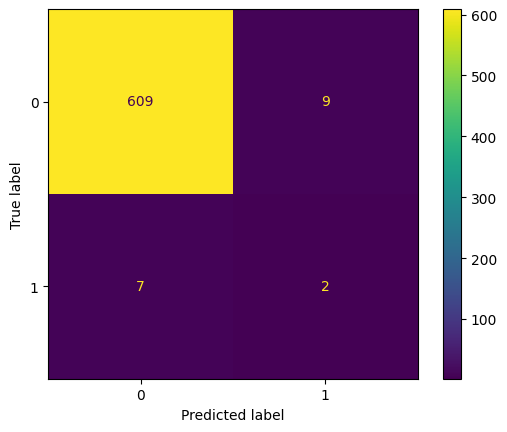

In [110]:
model.eval()
# Step 2: Predict on the test set
with torch.no_grad():

    logits = model(X_test_tensor)

    probabilities = torch.sigmoid(logits)

    predictions = (probabilities >= 0.5).int()
# Step 3: Convert to NumPy
y_pred = predictions.numpy().flatten()

y_prob = probabilities.numpy().flatten()
# Step 4: Calculate evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

print(confusion_matrix(y_test, y_pred))
# Step 5: Plot the confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(cm).plot()